In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LinearRegression

# Load the dataset
data = pd.read_csv('C:/Users/Joewo/Datasets/National_River_Toxin_Dataset_1.csv')

print("libraries imported successfully")

libraries imported successfully


In [2]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [3]:
# Loading into dataframe
df = pd.read_csv('C:/Users/Joewo/Datasets/National_River_Toxin_Dataset_1.csv')

# Initial Data Exploration

In [10]:
df.head()

,Date,River_System,pH_Level,Temperature,Lead,Mercury,Arsenic,Nitrates,Phosphates,Dissolved_Oxygen
0,2018-01-01,Amazon,7.030015,19.136212,2.500401,0.465454,3.578886,11.627614,0.522167,7.830196
1,2018-01-01,Nile,7.421766,21.406824,3.469443,0.859716,5.352155,10.538171,0.510465,8.130328
2,2018-01-01,Yangtze,7.133612,18.419902,3.806935,0.824085,5.277814,7.865033,0.585096,8.120874
3,2018-01-01,Mississippi,7.863001,18.014871,3.438131,0.500597,3.473881,11.143068,0.438248,6.853816
4,2018-01-01,Danube,7.527686,16.622289,2.188210,0.424178,2.454209,8.043467,0.422244,8.197925


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1305 entries, 0 to 1304
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Date              1305 non-null   str    
 1   River_System      1305 non-null   str    
 2   pH_Level          1278 non-null   float64
 3   Temperature       1278 non-null   float64
 4   Lead              1285 non-null   float64
 5   Mercury           1278 non-null   float64
 6   Arsenic           1279 non-null   float64
 7   Nitrates          1265 non-null   float64
 8   Phosphates        1282 non-null   float64
 9   Dissolved_Oxygen  1284 non-null   float64
dtypes: float64(8), str(2)
memory usage: 102.1 KB


In [11]:
df.describe()

,pH_Level,Temperature,Lead,Mercury,Arsenic,Nitrates,Phosphates,Dissolved_Oxygen
count,1278.000000,1278.000000,1285.000000,1278.000000,1279.000000,1265.000000,1282.000000,1284.000000
mean,7.353247,20.041668,3.011035,0.596108,3.597916,10.038789,0.497162,8.023795
std,0.349114,4.063638,0.874431,0.175150,0.992052,2.096641,0.106304,1.064190
min,6.465087,9.891618,0.551349,0.157117,1.485608,2.025075,0.144044,5.041394
25%,7.101324,16.813976,2.366298,0.462683,2.836160,8.701188,0.422006,7.269386
50%,7.339326,20.039121,3.000714,0.599186,3.511678,10.089112,0.497631,8.007448
75%,7.585733,23.358634,3.676560,0.734863,4.298946,11.391686,0.572888,8.740828
max,8.392902,30.749449,5.800963,1.057494,6.232902,16.547073,0.870007,11.228677


# Data Cleaning

In [12]:
# Checking for missing values
df.isnull().sum()

Date                 0
River_System         0
pH_Level            27
Temperature         27
Lead                20
Mercury             27
Arsenic             26
Nitrates            40
Phosphates          23
Dissolved_Oxygen    21
dtype: int64

In [20]:
# Filling missing values in numeric columns only
numeric_columns = df.select_dtypes(include=[np.number]).columns

df[numeric_columns] = df[numeric_columns].fillna(df[numeric_columns].mean())

In [21]:
# Checking missing values were replaced successfully
df.isnull().sum()

Date                0
River_System        0
pH_Level            0
Temperature         0
Lead                0
Mercury             0
Arsenic             0
Nitrates            0
Phosphates          0
Dissolved_Oxygen    0
dtype: int64

In [18]:
# Converting 'Date' column to datetime
df['Date'] = pd.to_datetime(data['Date'])

# Exploratory Data Analysis

In [25]:
# Calculating the average level of toxins
average_toxin_levels = df[['Lead', 'Mercury', 'Arsenic']].mean()

print(f'Average Toxin Levels:\n{average_toxin_levels}')

Average Toxin Levels:
Lead       3.011035
Mercury    0.596108
Arsenic    3.597916
dtype: float64


In [28]:
# Find top polluted rivers by average lead levels
top_polluted_rivers = data.groupby('River_System')['Lead'].mean().sort_values(ascending=False)

print(f'Top Polluted Rivers by Lead Levels:\n{top_polluted_rivers.head()}')

Top Polluted Rivers by Lead Levels:
River_System
Yangtze        4.022830
Mississippi    3.489190
Nile           2.989879
Danube         2.539492
Amazon         2.015404
Name: Lead, dtype: float64


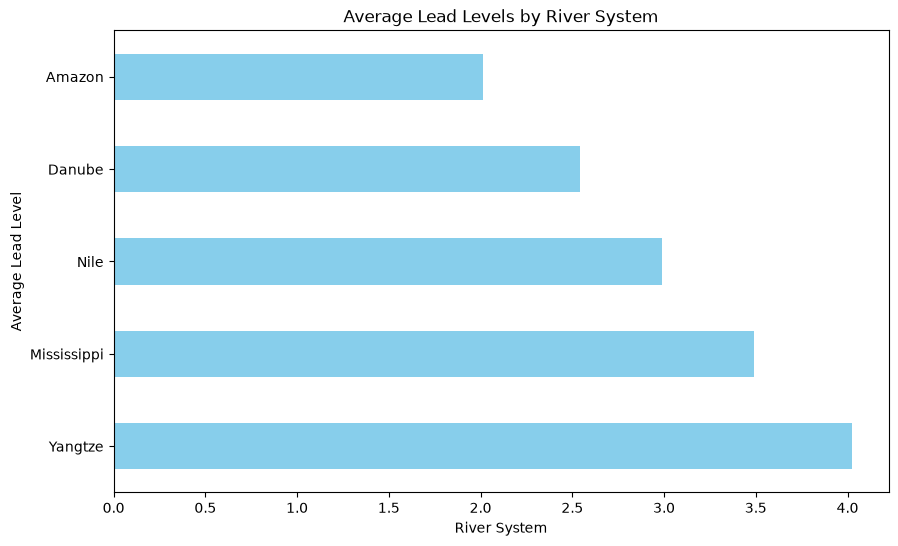

In [31]:
# Bar chart for average lead levels per river
plt.figure(figsize=(10,6))
top_polluted_rivers.plot(kind='barh', color='skyblue')
plt.title('Average Lead Levels by River System')
plt.xlabel('River System')
plt.ylabel('Average Lead Level')
plt.show()

<Figure size 1000x600 with 0 Axes>

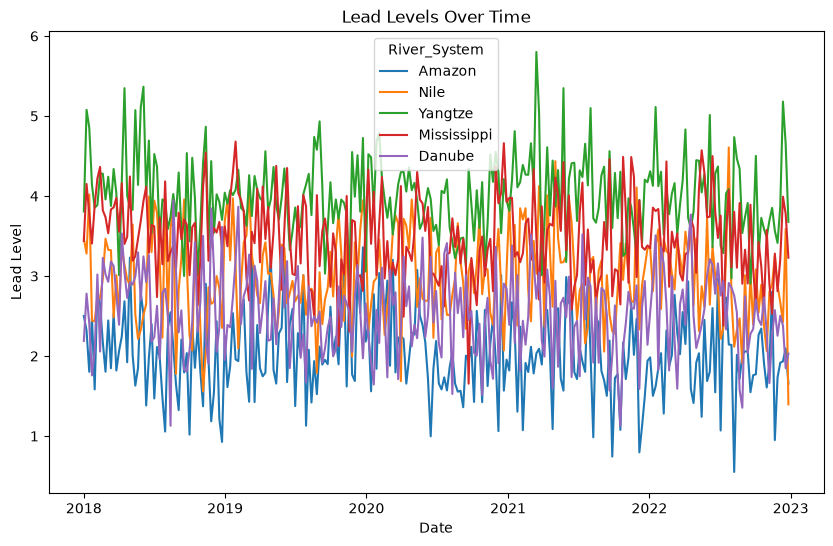

In [35]:
# Line graph for toxin levels over time
plt.figure(figsize=(10,6))
plt.figure(figsize=(10,6))
sns.lineplot(x='Date', y='Lead', data=df, hue='River_System', errorbar=None)
errorbar=None
plt.title('Lead Levels Over Time')
plt.xlabel('Date')
plt.ylabel('Lead Level')
plt.show()

In [44]:
# Computing the correlation matrix using only numeric columns
corr_matrix = df[numeric_columns].corr()

In [50]:
# Analysing the correlation between pH levels and toxin concentrations
ph_toxin_correlation = corr_matrix['pH_Level'][['Lead','Mercury','Arsenic']]

print(f'Correlation Between pH and Toxin Levels:\n{ph_toxin_correlation.head()}')

Correlation Between pH and Toxin Levels:
Lead       0.319700
Mercury    0.137656
Arsenic    0.042514
Name: pH_Level, dtype: float64


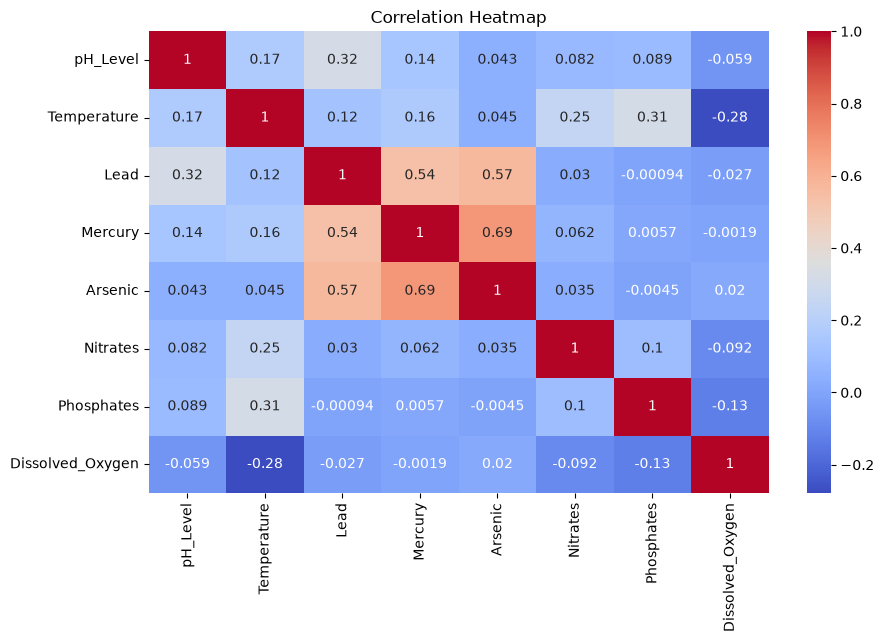

In [51]:
# Heatmap for correlation between different parameters
plt.figure(figsize=(10,6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

In [56]:
# T-test between two river systems (Amazon and Nile)
amazon_data = df[df['River_System'] == 'Amazon']['Lead']
nile_data = df[df['River_System'] == 'Nile']['Lead']
t_stat,p_value = stats.ttest_ind(amazon_data, nile_data)

print(f'T-test between Amazon and Nile: T-statistic = {t_stat}, P-value = {p_value}')

T-test between Amazon and Nile: T-statistic = -20.23821779031797, P-value = 1.3375120881428784e-67


In [59]:
# Linear regression analysis for lead levels and pH
X = df[['pH_Level']]
y= df['Lead']
model = LinearRegression()
model.fit(X,y)

print(f'Linear Regression Coefficient: {model.coef_}')
print(f'Linear Regression Intercept: {model.intercept_}')

Linear Regression Coefficient: [0.80294889]
Linear Regression Intercept: -2.893246694927761
